# Pretrain a U-Net network to be the teacher of SAM Adapter

In [1]:
# Cell 1: 准备环境
import sys
import os
import matplotlib.pyplot as plt
import torch

# 将项目根目录加入 path，这样才能 import src_unet
sys.path.append("..") 

from src_unet.config import Config
from src_unet.dataset import get_dataloaders

# 覆盖配置 (如果需要测试小批量)
# Config.DATA_ROOT = "/home/maia-user/yufeng/Data/BUS_Mix_Seg" # 注意相对路径
# Config.BATCH_SIZE = 4
Config.NUM_WORKERS = 0


In [2]:

# Cell 2: 加载数据
print("正在加载 DataLoader...")
train_loader, val_loader = get_dataloaders()
print("加载完成！")


正在加载 DataLoader...
找到 5272 张图像 和 5272 个标签
配对完成的文件数: 5272
训练集样本数: 4217, 验证集样本数: 1055
数据集创建完成
数据加载器创建完成
加载完成！


当前 Batch 的文件名: ['BUET_10-07-31', 'BrEaST_case143', 'BUSUC_00100', 'UDIAT_000130', 'BUSUC_0044', 'BUSIS_case309', 'BUSIS_case146', 'BUSBRA_0390-l']


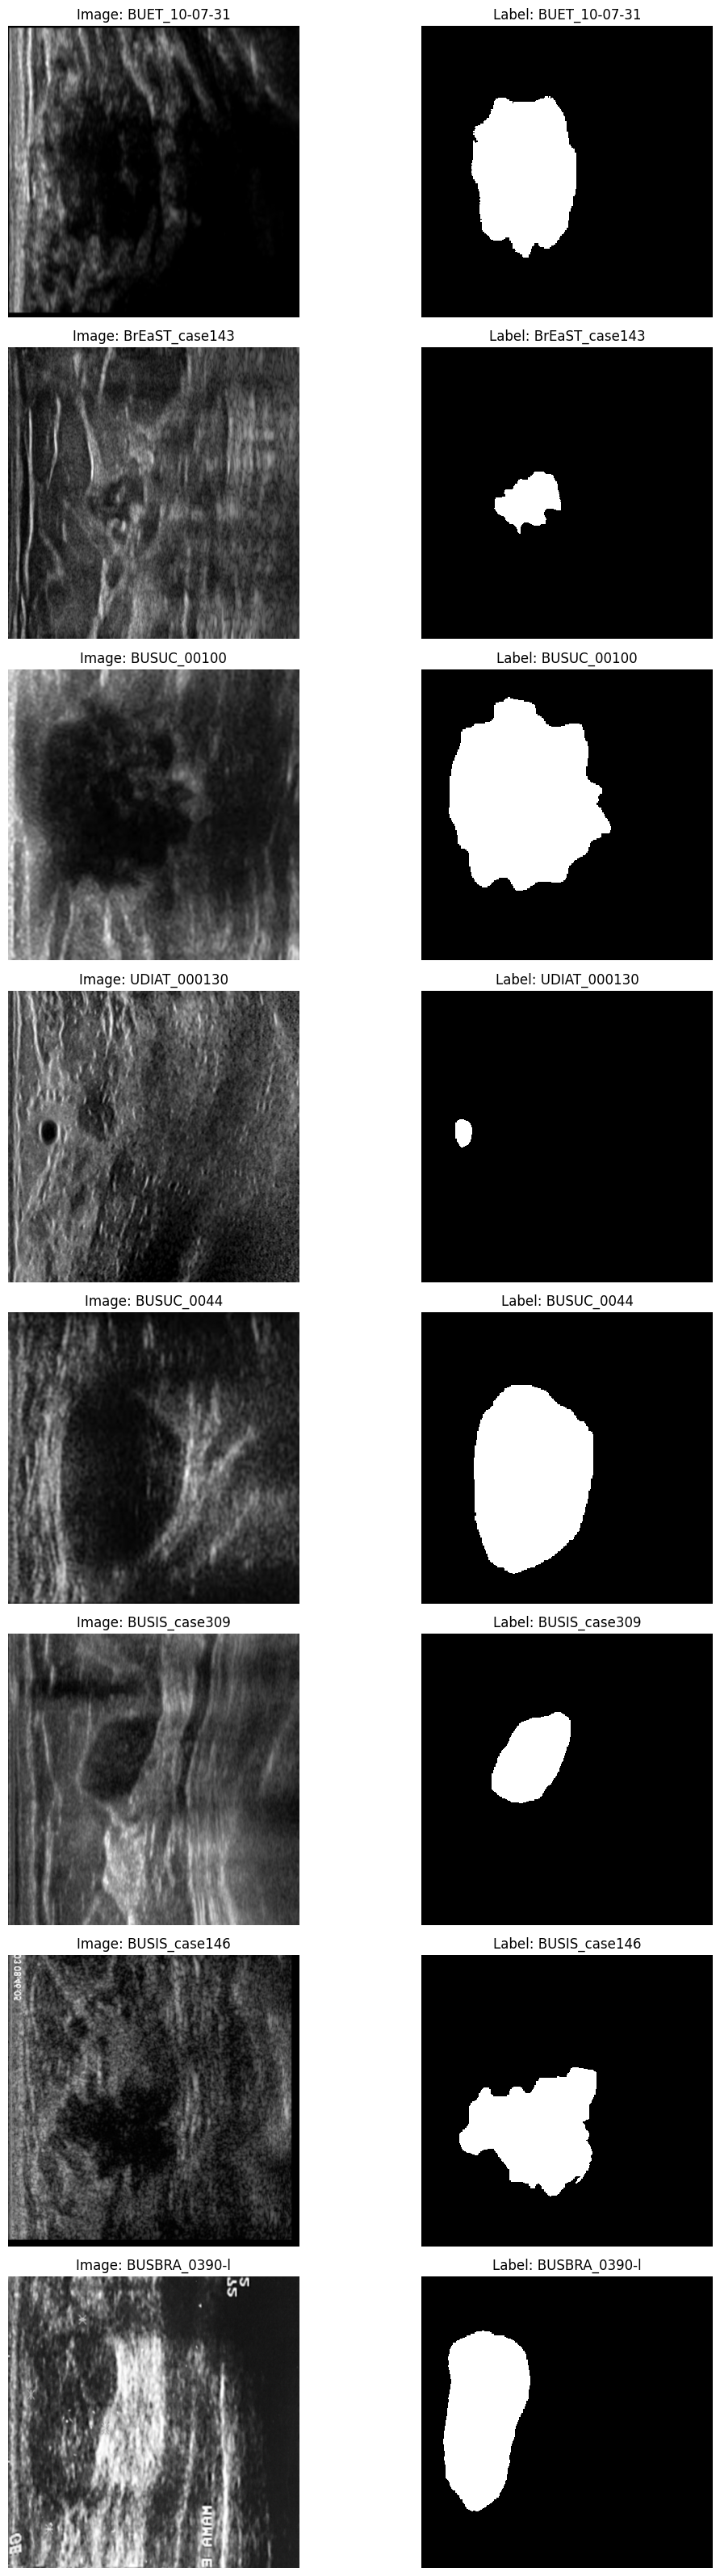

In [4]:
batch = next(iter(val_loader))
images = batch["image"]
masks = batch["label"]

# === 🔴 获取文件名列表 ===
# MONAI 会自动把 metadata 收集到一个列表里
# 注意：image_meta_dict 是一个字典，但里面的值是 list (长度等于 batch_size)
file_paths = batch["image_meta_dict"]["filename_or_obj"]

# 提取纯文件名 (去掉路径和后缀)
# 例如: '/data/images/case123.png' -> 'case123'
filenames = [os.path.splitext(os.path.basename(p))[0] for p in file_paths]

print(f"当前 Batch 的文件名: {filenames}")

# 2. 可视化函数
def show_batch_with_name(imgs, msks, names):
    batch_size = len(imgs)
    plt.figure(figsize=(12, 4 * batch_size)) # 调整画布大小
    
    for i in range(batch_size):
        # Image
        plt.subplot(batch_size, 2, 2*i + 1)
        # 获取第 i 张图的第 0 个通道 (C, H, W) -> (H, W)
        # 加上 .cpu() 确保在 CPU 上绘图
        img_data = imgs[i, 0, :, :].detach().cpu()
        plt.imshow(img_data, cmap="gray")
        plt.title(f"Image: {names[i]}") # <--- 显示名字
        plt.axis("off")
        
        # Label
        plt.subplot(batch_size, 2, 2*i + 2)
        msk_data = msks[i, 0, :, :].detach().cpu()
        plt.imshow(msk_data, cmap="gray", interpolation="nearest") # jet 颜色看 mask 更清楚
        plt.title(f"Label: {names[i]}") # <--- 显示名字
        plt.axis("off")
        
    plt.tight_layout()
    plt.show()

# 3. 运行可视化
show_batch_with_name(images, masks, filenames)